In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df_scaled = pd.read_csv(
    "../data/processed/03_data_transformation.csv"
)

X_scaled = df_scaled.values

print("Ukuran data:", X_scaled.shape)
display(df_scaled.head())


Ukuran data: (758, 7)


,price_idr,ram_gb,storage_gb,clock_speed_ghz,battery_mah,rear_camera_main_mp,charging_watt
0,-0.619544,0.002948,-0.549736,-1.674962,-0.381359,-0.759433,-1.252647
1,-0.716578,-1.274071,-0.549736,-2.178513,-2.157638,-1.472522,-1.252647
2,-0.619575,-1.274071,-0.549736,-0.500008,-0.381359,-1.472522,-1.252647
3,-0.528547,-1.274071,-0.549736,-0.332158,0.639491,-1.472522,-1.078585
4,-0.558879,-1.274071,-0.930111,-0.332158,0.639491,-1.472522,-1.078585


In [2]:

inertia_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

elbow_df = pd.DataFrame({
    "Jumlah Cluster (K)": list(k_values),
    "Inertia": inertia_values
})

display(elbow_df)


,Jumlah Cluster (K),Inertia
0,1,5306.000000
1,2,3696.670616
2,3,2846.572958
3,4,2507.627479
4,5,2188.657232
5,6,2004.264322
6,7,1754.456301
7,8,1576.441430
8,9,1465.655939
9,10,1318.219726


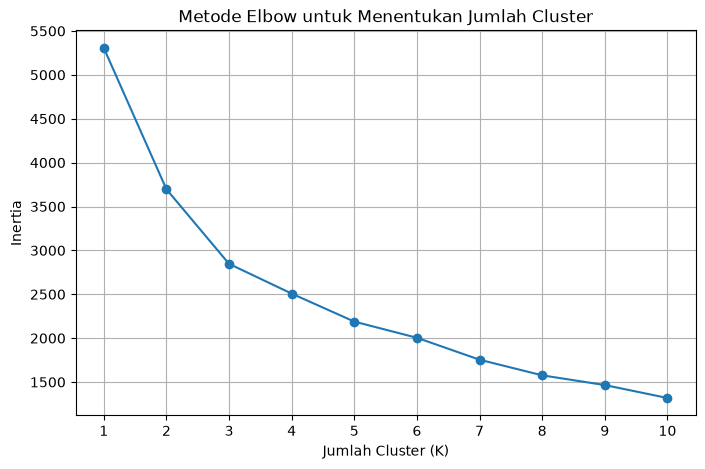

In [3]:

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Metode Elbow untuk Menentukan Jumlah Cluster")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


In [4]:

silhouette_values = []
silhouette_k_values = range(2, 11)

for k in silhouette_k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    silhouette_values.append(score)

silhouette_df = pd.DataFrame({
    "Jumlah Cluster (K)": list(silhouette_k_values),
    "Silhouette Score": silhouette_values
})

display(silhouette_df)


,Jumlah Cluster (K),Silhouette Score
0,2,0.387838
1,3,0.357472
2,4,0.238936
3,5,0.254312
4,6,0.258743
5,7,0.264143
6,8,0.268435
7,9,0.238392
8,10,0.236666


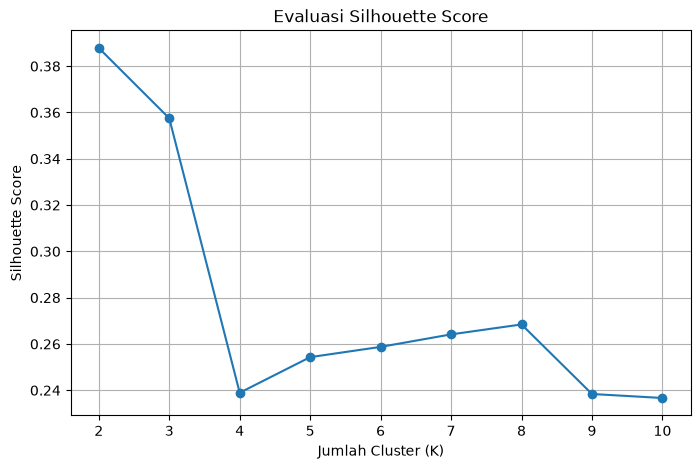

In [5]:

plt.figure(figsize=(8, 5))

plt.plot(
    list(silhouette_k_values),
    silhouette_values,
    marker="o"
)

plt.title("Evaluasi Silhouette Score")
plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(silhouette_k_values))
plt.grid(True)
plt.show()


In [6]:

best_k_silhouette = int(
    silhouette_df.loc[
        silhouette_df["Silhouette Score"].idxmax(),
        "Jumlah Cluster (K)"
    ]
)

best_score = silhouette_df["Silhouette Score"].max()

print("K dengan Silhouette Score tertinggi:", best_k_silhouette)
print("Silhouette Score tertinggi:", round(best_score, 4))


K dengan Silhouette Score tertinggi: 2
Silhouette Score tertinggi: 0.3878


In [7]:

final_k = best_k_silhouette

kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_scaled)

print("Jumlah cluster final:", final_k)
print("Silhouette Score model final:",
      round(silhouette_score(X_scaled, cluster_labels), 4))


Jumlah cluster final: 2
Silhouette Score model final: 0.3878


In [8]:

# Membaca data yang memiliki identitas smartphone
df_original = pd.read_csv(
    "../data/processed/02_feature_engineering.csv"
)

# Memastikan urutan dan jumlah baris sesuai
assert len(df_original) == len(cluster_labels), \
    "Jumlah baris data tidak sama!"

# Menambahkan label cluster
df_cluster = df_original.copy()
df_cluster["cluster"] = cluster_labels

# Menyimpan hasil clustering
output_path = "../outputs/cluster_result.csv"
df_cluster.to_csv(output_path, index=False)

print("Clustering berhasil disimpan!")
print("Lokasi:", output_path)
print("Jumlah data:", len(df_cluster))

print("\nJumlah smartphone per cluster:")
display(
    df_cluster["cluster"]
    .value_counts()
    .sort_index()
    .rename("jumlah_smartphone")
    .to_frame()
)

display(df_cluster.head())


Clustering berhasil disimpan!
Lokasi: ../outputs/cluster_result.csv
Jumlah data: 758

Jumlah smartphone per cluster:


,jumlah_smartphone
cluster,
0,227
1,531


,smartphone_brand,model,price_idr,ram_gb,storage_gb,clock_speed_ghz,battery_mah,rear_camera_main_mp,charging_watt,cluster
0,blackzone,BlackZone S25 Ultra Maxx,1711790,8,128,1.6,5000,32.0,10.0,1
1,ringme,Ringme Bold P70,1103276,4,128,1.3,3260,13.0,10.0,1
2,lava,Lava Shark 5G (4GB RAM + 128GB),1711600,4,128,2.3,5000,13.0,10.0,1
3,vivo,Vivo Y19s 5G (4GB RAM + 128GB),2282450,4,128,2.4,6000,13.0,15.0,1
4,vivo,Vivo Y19s 5G (4GB RAM + 64GB),2092230,4,64,2.4,6000,13.0,15.0,1


In [10]:

# Membandingkan karakteristik setiap cluster
cluster_summary = df_cluster.groupby("cluster")[
    [
        "price_idr",
        "ram_gb",
        "storage_gb",
        "clock_speed_ghz",
        "battery_mah",
        "rear_camera_main_mp",
        "charging_watt"
    ]
].mean().round(2)

display(cluster_summary)


,price_idr,ram_gb,storage_gb,clock_speed_ghz,battery_mah,rear_camera_main_mp,charging_watt
cluster,,,,,,,
0,11526852.03,11.33,378.93,3.25,5491.06,61.19,70.44
1,3062087.96,6.56,152.77,2.32,5323.34,48.41,35.53
